# NutriRota — Análise territorial das feiras livres de São Paulo

## 1. Contexto e objetivo

Este notebook explora a relação municipal de feiras livres disponibilizada pela Prefeitura de São Paulo. O objetivo é compreender como os registros se distribuem por **subprefeitura**, **dia de funcionamento** e **categoria**, oferecendo contexto territorial para o projeto NutriRota.

A base contém 933 registros extraídos do PDF municipal. Ela descreve cadastro e localização das feiras, mas **não contém medidas de desperdício de alimentos**. Assim, os resultados são descritivos e não permitem estimar desperdício por feira.

## 2. Fonte, unidade de análise e cautelas

- Fonte: relação de endereços das feiras livres da Prefeitura de São Paulo.
- Unidade de análise: registro de feira listado no documento.
- Campos utilizados: subprefeitura, dia, categoria, quantidade de feirantes, nome, tipo de logradouro, logradouro e bairro.
- A extração do PDF pode produzir ruídos de OCR, abreviações e deslocamentos entre colunas. Os valores originais são preservados em colunas `*_original`; as padronizações analíticas são explícitas e reversíveis.


In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Constante reutilizada nos gráficos e tabelas
ROTULO_QUANTIDADE_REGISTROS = "Quantidade de registros"

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

RAIZ = Path.cwd().parent
CAMINHO_BASE = RAIZ / "data" / "processed" / "prefeitura_sp_feiras_livres_normalizado.csv"

df = pd.read_csv(
    CAMINHO_BASE,
    sep=";",
    encoding="utf-8-sig",
    dtype=str
)

print("Base carregada:", df.shape[0], "registros e", df.shape[1], "colunas")
display(df.head())


Base carregada: 933 registros e 9 colunas


,subprefeitura,dia_feira,categoria,quantidade_feirantes,nome_feira,tipo_logradouro,logradouro,bairro,pagina_pdf
0,ARICANDUVA I FORMOSA I CARRAO,DOM,TRADICIONAL,88,VILA FORMOSA,AV,TRUMAIN C/ HENRIQUE MORIZE,VL FORMOSA,1
1,ARICANDUVA I FORMOSA I CARRAO,DOM,TRADICIONAL,81,VILA CARRAO,RUA,COMEN GIL PINHEIRO,VL CALIFORNIA,1
2,ARICANDUVA I FORMOSA I CARRAO,DOM,TRADICIONAL,71,VILA RICA,RUA,PROF ALZIRA DE O GILIOLI,VL RICA,1
3,ARICANDUVA I FORMOSA I CARRAO,DOM,TRADICIONAL,43,VILA SANTA IZABEL,RUA,LUIS PINTO,VL CARRAO,1
4,ARICANDUVA I FORMOSA I CARRAO,TER,ÔRGANICA,21,FEIRA LIVRE DE ORGANICOS CERET,RUA,ELEONORA CINTRA,JD ANALIA FRANCO,1


## 3. Integridade e visão geral

Antes de contar feiras por território, verificamos campos ausentes, duplicidades exatas e os valores distintos dos campos categóricos. A contagem de registros representa as linhas do cadastro extraído; não é uma contagem independente de unidades operacionais ativas.


In [2]:
# Resumo de ausências e duplicidades
resumo_integridade = pd.DataFrame({
    "valores_ausentes": df.isna().sum(),
    "textos_vazios": (df.fillna("").apply(lambda coluna: coluna.str.strip().eq("")).sum()),
})

print("Dimensões:", df.shape)
print("Duplicidades exatas:", df.duplicated().sum())
display(resumo_integridade)

# Converter quantidade de feirantes para número, mantendo a coluna original
df["quantidade_feirantes_original"] = df["quantidade_feirantes"]
df["quantidade_feirantes_num"] = pd.to_numeric(
    df["quantidade_feirantes"],
    errors="coerce"
)

print("Registros sem quantidade numérica:", df["quantidade_feirantes_num"].isna().sum())
print("Registros com quantidade igual a zero:", (df["quantidade_feirantes_num"] == 0).sum())


Dimensões: (933, 9)
Duplicidades exatas: 0


,valores_ausentes,textos_vazios
subprefeitura,0,0
dia_feira,0,0
categoria,0,0
quantidade_feirantes,0,0
nome_feira,0,0
tipo_logradouro,0,0
logradouro,0,0
bairro,0,0
pagina_pdf,0,0


Registros sem quantidade numérica: 0
Registros com quantidade igual a zero: 23


In [3]:
# Estatísticas da quantidade de feirantes nos registros com valor positivo
quantidades_positivas = df.loc[
    df["quantidade_feirantes_num"] > 0,
    "quantidade_feirantes_num"
]

print("Estatísticas da quantidade de feirantes (excluindo os 23 zeros):")
display(quantidades_positivas.describe().round(2))

# Resumo por subprefeitura: total de registros, total de feirantes e média por registro
porte_por_subprefeitura = (
    df.groupby("subprefeitura", dropna=False)
    .agg(
        quantidade_registros=("quantidade_feirantes_num", "size"),
        registros_com_feirantes=("quantidade_feirantes_num", lambda serie: (serie > 0).sum()),
        soma_feirantes_por_registro=("quantidade_feirantes_num", "sum"),
        media_feirantes_por_registro=("quantidade_feirantes_num", "mean"),
        media_feirantes_registros_positivos=("quantidade_feirantes_num", lambda serie: serie[serie > 0].mean())
    )
    .reset_index()
    .sort_values("soma_feirantes_por_registro", ascending=False)
)

display(porte_por_subprefeitura.round(2))


Estatísticas da quantidade de feirantes (excluindo os 23 zeros):


count    910.00
mean      50.71
std       37.92
min        1.00
25%       20.00
50%       43.00
75%       72.00
max      228.00
Name: quantidade_feirantes_num, dtype: float64

,subprefeitura,quantidade_registros,registros_com_feirantes,soma_feirantes_por_registro,media_feirantes_por_registro,media_feirantes_registros_positivos
19,PENHA,54,52,2686,49.74,51.65
17,MOOCA,48,48,2575,53.65,53.65
27,SE,38,37,2530,66.58,68.38
29,VILA MARIANA,38,38,2521,66.34,66.34
30,VILA PRUDENTE / SAPOPEMBA,50,47,2453,49.06,52.19
10,IPIRANGA,48,48,2174,45.29,45.29
12,ITAQUERA,43,42,2103,48.91,50.07
26,SAO MIGUEL,32,31,1919,59.97,61.90
28,V MARIA / VILA GUILHERME,29,29,1796,61.93,61.93
25,SAO MATEUS,38,37,1728,45.47,46.70


A quantidade de feirantes é utilizada aqui como indicador cadastral de porte operacional. As estatísticas gerais consideram apenas os 910 registros com valor positivo; os 23 zeros permanecem preservados e são contabilizados separadamente. Na tabela por subprefeitura, `soma_feirantes_por_registro` é a soma dos quantitativos cadastrados em cada linha do documento: não representa pessoas únicas nem elimina possíveis repetições de uma feira em dias diferentes. `media_feirantes_por_registro` inclui os registros com zero; `media_feirantes_registros_positivos` considera somente registros com quantidade maior que zero. Nenhuma dessas medidas representa vendas ou volume de abastecimento.


## 4. Padronização conservadora dos dias e categorias

As padronizações abaixo corrigem apenas variações reconhecíveis e mantêm o conteúdo original. `SAB` e `SÁB` são unificados como `SÁB`. O registro `QUA NOTURNA` é separado em dia `QUA` e observação de período `NOTURNA`, preservando o texto original em `dia_feira_original`.

As categorias `ORGÂNICA` e `ÔRGANICA` são unificadas como `ORGÂNICA`. Não são feitas correções automáticas de logradouro ou tipo de logradouro quando o contexto não permite determinar com segurança o texto pretendido.


In [4]:
# Preservar os campos originais antes de normalizar
df["dia_feira_original"] = df["dia_feira"]
df["categoria_original"] = df["categoria"]
df["tipo_logradouro_original"] = df["tipo_logradouro"]
df["logradouro_original"] = df["logradouro"]

# Normalizar espaços e caixa dos campos categóricos
df["dia_analise"] = df["dia_feira"].fillna("").str.strip().str.upper()
df["periodo_observado"] = "NAO INFORMADO"

# Separar o caso específico QUA NOTURNA sem perder a informação
mascara_quarta_noturna = df["dia_analise"].eq("QUA NOTURNA")
df.loc[mascara_quarta_noturna, "dia_analise"] = "QUA"
df.loc[mascara_quarta_noturna, "periodo_observado"] = "NOTURNA"

# Unificar variantes de sábado
df["dia_analise"] = df["dia_analise"].replace({
    "SAB": "SÁB",
    "SÁB": "SÁB"
})

# Padronizar categoria orgânica, corrigindo a variante com acento deslocado
df["categoria_analise"] = df["categoria"].fillna("").str.strip().str.upper()
df["categoria_analise"] = df["categoria_analise"].replace({
    "ÔRGANICA": "ORGÂNICA",
    "ORGANICA": "ORGÂNICA"
})

# Subprefeitura e campos territoriais: apenas espaços e caixa, sem alterar nomes
df["subprefeitura_analise"] = (
    df["subprefeitura"].fillna("").str.strip().str.upper()
)
df["bairro_analise"] = df["bairro"].fillna("").str.strip().str.upper()

print("Dias padronizados:")
display(df["dia_analise"].value_counts().rename_axis("dia").to_frame("registros"))
print("Categorias padronizadas:")
display(df["categoria_analise"].value_counts().rename_axis("categoria").to_frame("registros"))


Dias padronizados:


,registros
dia,
DOM,196
SÁB,182
QUA,158
QUI,135
SEX,134
TER,128


Categorias padronizadas:


,registros
categoria,
TRADICIONAL,903
NOTURNA,20
ORGÂNICA,10


## 5. Distribuição das feiras por subprefeitura

A contagem abaixo descreve quantos registros do cadastro aparecem associados a cada subprefeitura. Ela não representa número de barracas, volume comercializado ou desperdício.


,subprefeitura,quantidade_registros
0,PENHA,54
1,VILA PRUDENTE / SAPOPEMBA,50
2,IPIRANGA,48
3,MOOCA,48
4,ITAQUERA,43
5,PIRITUBA / JARAGUA,43
6,SE,38
7,SAO MATEUS,38
8,VILA MARIANA,38
9,BUTANTA,35


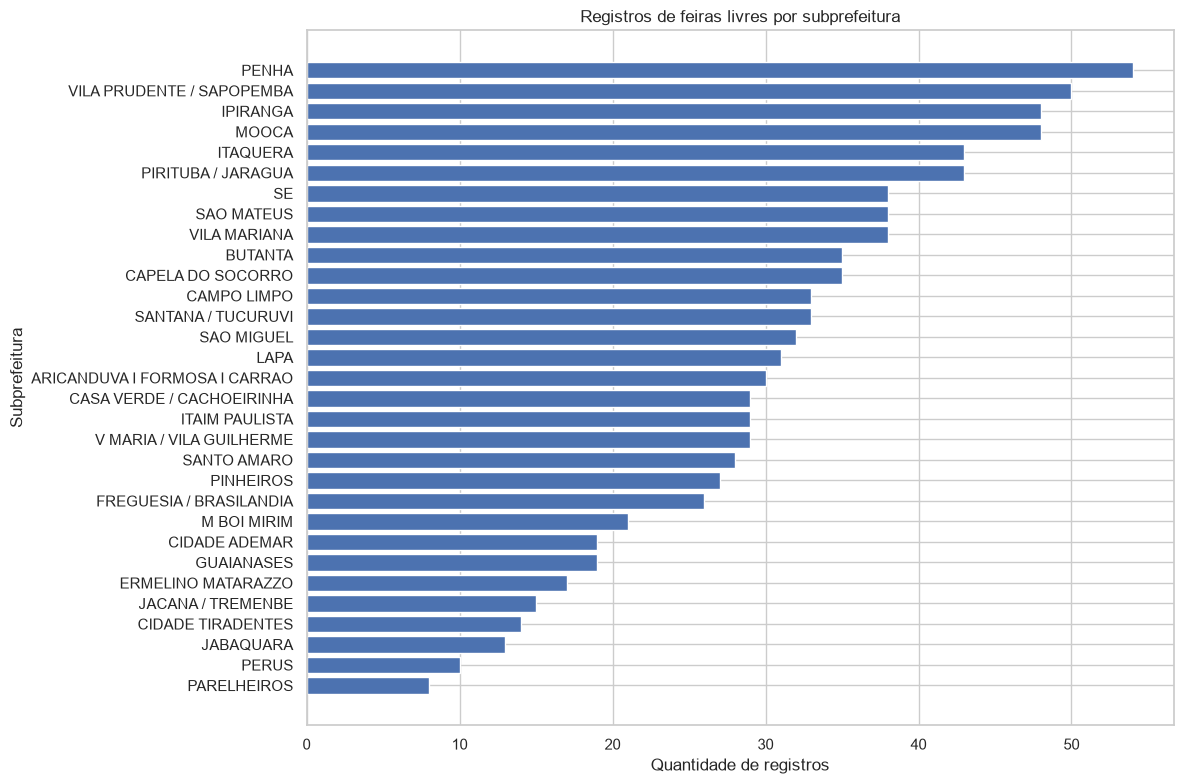

In [5]:
feiras_por_subprefeitura = (
    df["subprefeitura_analise"]
    .value_counts()
    .rename_axis("subprefeitura")
    .reset_index(name="quantidade_registros")
    .sort_values("quantidade_registros", ascending=False)
)

display(feiras_por_subprefeitura)

plt.figure(figsize=(12, 8))
plt.barh(
    feiras_por_subprefeitura["subprefeitura"],
    feiras_por_subprefeitura["quantidade_registros"]
)
plt.gca().invert_yaxis()
plt.title("Registros de feiras livres por subprefeitura")
plt.xlabel(ROTULO_QUANTIDADE_REGISTROS)
plt.ylabel("Subprefeitura")
plt.tight_layout()
plt.show()


## 6. Distribuição por dia da semana

A padronização unifica as duas grafias de sábado. O registro noturno de quarta-feira permanece contado em quarta-feira, com a observação de período separada para não criar um oitavo dia da semana.


,dia,quantidade_registros
0,TER,128
1,QUA,158
2,QUI,135
3,SEX,134
4,SÁB,182
5,DOM,196


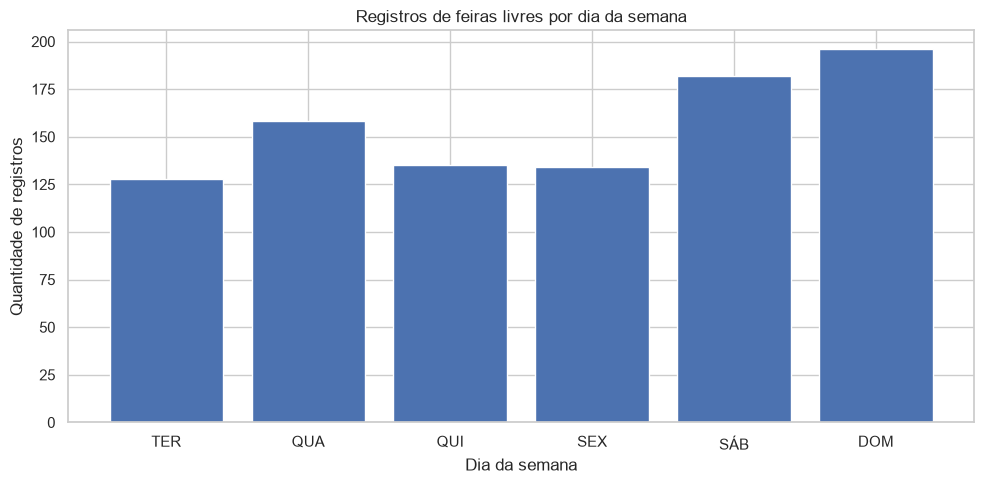

Registros marcados como noturnos:


,nome_feira,dia_feira_original,dia_analise,categoria_analise,subprefeitura
932,FEIRA LIVRE ORGANICA WHITAKER,QUA NOTURNA,QUA,ORGÂNICA,VILA MARIANA


In [6]:
ordem_dias = ["TER", "QUA", "QUI", "SEX", "SÁB", "DOM"]

feiras_por_dia = (
    df["dia_analise"]
    .value_counts()
    .reindex(ordem_dias, fill_value=0)
    .rename_axis("dia")
    .reset_index(name="quantidade_registros")
)

display(feiras_por_dia)

plt.figure(figsize=(10, 5))
plt.bar(
    feiras_por_dia["dia"],
    feiras_por_dia["quantidade_registros"]
)
plt.title("Registros de feiras livres por dia da semana")
plt.xlabel("Dia da semana")
plt.ylabel(ROTULO_QUANTIDADE_REGISTROS)
plt.tight_layout()
plt.show()

print("Registros marcados como noturnos:")
display(df[df["periodo_observado"] == "NOTURNA"][
    ["nome_feira", "dia_feira_original", "dia_analise", "categoria_analise", "subprefeitura"]
])


## 7. Distribuição por categoria cadastrada

A categoria do cadastro não deve ser confundida com categoria de alimento ou classificação de resíduo do estudo Brancoli. Aqui, `TRADICIONAL`, `NOTURNA` e `ORGÂNICA` descrevem categorias do registro municipal.


,categoria,quantidade_registros
0,TRADICIONAL,903
1,NOTURNA,20
2,ORGÂNICA,10


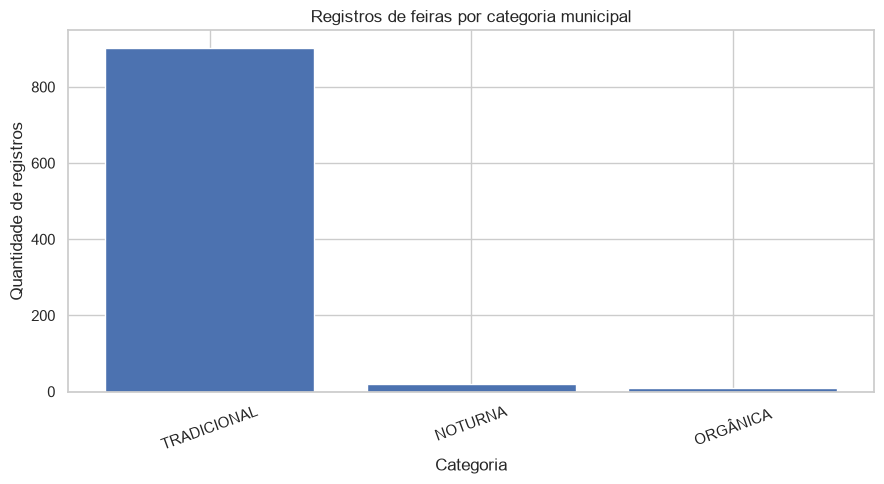

In [7]:
feiras_por_categoria = (
    df["categoria_analise"]
    .value_counts()
    .rename_axis("categoria")
    .reset_index(name="quantidade_registros")
    .sort_values("quantidade_registros", ascending=False)
)

display(feiras_por_categoria)

plt.figure(figsize=(9, 5))
plt.bar(
    feiras_por_categoria["categoria"],
    feiras_por_categoria["quantidade_registros"]
)
plt.title("Registros de feiras por categoria municipal")
plt.xlabel("Categoria")
plt.ylabel(ROTULO_QUANTIDADE_REGISTROS)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 8. Cruzamentos territoriais

Os cruzamentos ajudam a observar como os dias e categorias se distribuem no território. Como são contagens de registros do cadastro, diferenças podem refletir a organização e a cobertura do documento, e não necessariamente intensidade de atividade econômica.


dia_analise,TER,QUA,QUI,SEX,SÁB,DOM
subprefeitura_analise,,,,,,
ARICANDUVA I FORMOSA I CARRAO,5,6,4,4,7,4
BUTANTA,4,5,5,5,8,8
CAMPO LIMPO,2,4,5,4,8,10
CAPELA DO SOCORRO,3,6,3,2,10,11
CASA VERDE / CACHOEIRINHA,5,4,3,4,3,10
CIDADE ADEMAR,2,3,3,3,2,6
CIDADE TIRADENTES,0,2,1,2,3,6
ERMELINO MATARAZZO,2,1,5,2,4,3
FREGUESIA / BRASILANDIA,4,3,3,4,6,6


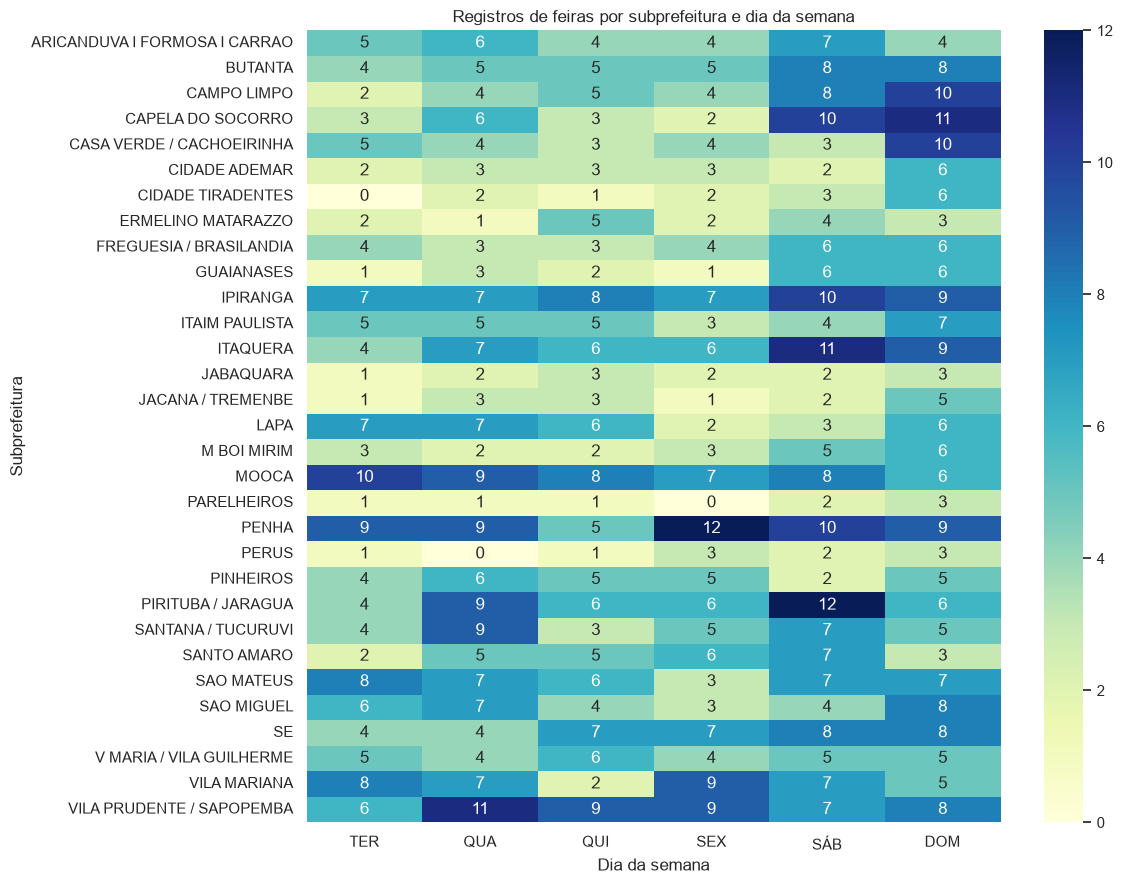

categoria_analise,NOTURNA,ORGÂNICA,TRADICIONAL
subprefeitura_analise,,,
ARICANDUVA I FORMOSA I CARRAO,1,1,28
BUTANTA,0,0,35
CAMPO LIMPO,0,1,32
CAPELA DO SOCORRO,0,0,35
CASA VERDE / CACHOEIRINHA,0,0,29
CIDADE ADEMAR,0,0,19
CIDADE TIRADENTES,0,0,14
ERMELINO MATARAZZO,1,0,16
FREGUESIA / BRASILANDIA,0,0,26


In [8]:
tabela_subprefeitura_dia = pd.crosstab(
    df["subprefeitura_analise"],
    df["dia_analise"]
).reindex(columns=ordem_dias, fill_value=0)

display(tabela_subprefeitura_dia)

plt.figure(figsize=(12, 9))
sns.heatmap(
    tabela_subprefeitura_dia,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)
plt.title("Registros de feiras por subprefeitura e dia da semana")
plt.xlabel("Dia da semana")
plt.ylabel("Subprefeitura")
plt.tight_layout()
plt.show()

tabela_subprefeitura_categoria = pd.crosstab(
    df["subprefeitura_analise"],
    df["categoria_analise"]
)
display(tabela_subprefeitura_categoria)


## 9. Auditoria de possíveis ruídos residuais da extração

A auditoria destaca valores que merecem conferência visual no PDF original. A sinalização não significa que o valor esteja necessariamente errado: abreviações podem ser legítimas, e o texto extraído pode ter limitações de OCR ou de estrutura tabular.

Não corrigimos automaticamente os valores de `tipo_logradouro` e `logradouro` que exigem interpretação contextual. O arquivo original permanece preservado e esta tabela serve como fila de revisão manual.


In [9]:
# Auditoria direcionada de possíveis ruídos residuais da extração do PDF
# Cruzamentos com "C/" são preservados: essa forma pode indicar um endereço válido.

campos_revisao = [
    "dia_feira_original",
    "categoria_original",
    "tipo_logradouro_original",
    "logradouro_original",
    "nome_feira",
    "bairro"
]

termos_suspeitos = [
    "PRA A DO FORRO",
    "P ARAISO",
    "PRA A",
    "P ARA",
    "Þ",
    "Ãƒ",
    "Ã‚"
]

linhas_revisao = []

for campo in campos_revisao:
    contagens = df[campo].fillna("").value_counts()

    for valor, quantidade in contagens.items():
        valor_texto = str(valor).strip()
        valor_maiusculo = valor_texto.upper()
        suspeito = False
        motivo = ""

        if campo == "dia_feira_original" and valor_maiusculo not in [
            "SEG", "TER", "QUA", "QUI", "SEX", "SAB", "SÁB", "DOM", "QUA NOTURNA"
        ]:
            suspeito = True
            motivo = "Valor de dia fora do conjunto esperado"

        elif campo == "categoria_original" and valor_maiusculo not in [
            "TRADICIONAL", "NOTURNA", "ORGÂNICA", "ÔRGANICA", "ORGANICA"
        ]:
            suspeito = True
            motivo = "Categoria fora do conjunto esperado"

        elif campo == "tipo_logradouro_original" and valor_maiusculo in [
            "P A", "OR UA", "TRA"
        ]:
            suspeito = True
            motivo = "Possível sangramento ou fragmento de coluna"

        elif campo in ["nome_feira", "bairro", "logradouro_original"]:
            for termo in termos_suspeitos:
                if termo in valor_maiusculo:
                    suspeito = True
                    motivo = "Possível ruído de OCR ou caractere corrompido"
                    break

        if suspeito:
            linhas_revisao.append({
                "campo": campo,
                "valor": valor_texto,
                "frequencia": quantidade,
                "motivo_revisao": motivo
            })

auditoria_residual = pd.DataFrame(linhas_revisao)

if not auditoria_residual.empty:
    auditoria_residual = auditoria_residual.sort_values(
        ["campo", "frequencia"],
        ascending=[True, False]
    )

display(auditoria_residual)


,campo,valor,frequencia,motivo_revisao
4,bairro,P ARAISO,1,Possível ruído de OCR ou caractere corrompido
3,nome_feira,PRA A DO FORRO,1,Possível ruído de OCR ou caractere corrompido
0,tipo_logradouro_original,P A,2,Possível sangramento ou fragmento de coluna
1,tipo_logradouro_original,OR UA,1,Possível sangramento ou fragmento de coluna
2,tipo_logradouro_original,TRA,1,Possível sangramento ou fragmento de coluna


## 10. Fechamento — leitura territorial e limitações

### Síntese

Esta análise permite descrever a distribuição dos registros municipais por subprefeitura, dia de funcionamento e categoria cadastrada. Os cruzamentos ajudam a identificar concentração territorial e diferenças de calendário entre regiões.

### Leitura dos agrupamentos territoriais

- O cadastro apresenta **31 agrupamentos de subprefeitura** porque o documento municipal lista **Vila Prudente / Sapopemba** em uma única linha/agrupamento. Portanto, não se deve interpretar esse total como 32 subprefeituras individualizadas nesta extração.
- Não há registros de segunda-feira (`SEG`) no arquivo analisado; por isso, o gráfico de dias começa na terça-feira.
- As subprefeituras Mooca (48 registros) e Sé (38 registros) somam **86 de 933 registros (9,2%)**. No Notebook 1, as quatro feiras do estudo Brancoli estão localizadas nessas duas subprefeituras. Esse cruzamento conecta a amostra científica ao panorama municipal, sem significar que as 86 feiras tenham dados de desperdício.

### Limitações

- A base é uma extração de um PDF municipal e pode conter abreviações, ruídos de OCR e ambiguidades de estrutura tabular.
- O número de registros não equivale necessariamente ao número de feiras únicas ativas: um mesmo nome pode aparecer em dias ou locais diferentes.
- Valores iguais a zero em `quantidade_feirantes` foram preservados; não há evidência suficiente nesta base para concluir que a feira esteja inativa.
- A categoria municipal não representa tipo de alimento nem classificação de desperdício.
- A base não possui pesagem de resíduos, excedente alimentar, vendas ou estoque por feira. Portanto, não pode ser usada diretamente para treinar um modelo de previsão de desperdício.

A quantidade de feirantes é uma métrica de porte operacional disponível no cadastro, mas os valores iguais a zero foram excluídos das estatísticas de porte e mantidos na base original. A média por subprefeitura deve ser interpretada como média dos registros cadastrados, não como capacidade total ou volume comercializado.

### Relação com o NutriRota

A base municipal fornece a camada territorial do projeto. Para avançar à modelagem, será necessário encontrar ou construir, com método documentado, observações de desperdício/excedente por feira e período, ou definir um alvo alternativo que seja efetivamente observável. Variáveis de clima, calendário, perfil territorial e preços podem ser avaliadas como explicativas, desde que tenham granularidade e cobertura compatíveis com o alvo.
